In [1]:
import numpy as np
from pycvxset import Polytope
from adaptive_tools import SetUpdater
from invariance_tools import GainSynthesis
from cartesian_product import cartesian_product

In [2]:
npzfile = np.load('system_matrices.npz')
A, B = npzfile['arr_0'], npzfile['arr_1']
A_B=np.concatenate( (A, B), axis=1).transpose(2, 0, 1)
C = np.array([[1.0, 0.0, 0.0, 0.0], [0.0, 1.0, 0.0, 0.0]])
C = np.stack([C, np.zeros((2, 4)), np.zeros((2, 4)), np.zeros((2, 4))], axis=2)
W = Polytope(
                A=np.block([[np.eye(4)], [-np.eye(4)]]), b=0.001 * np.ones((8, 1))
            )

E = Polytope(
                A=np.vstack((np.eye(2), -np.eye(2))),
                b=np.concatenate((np.ones(2) * 0.01, np.ones(2) * 0.01)),
            )

Theta_c = Polytope()

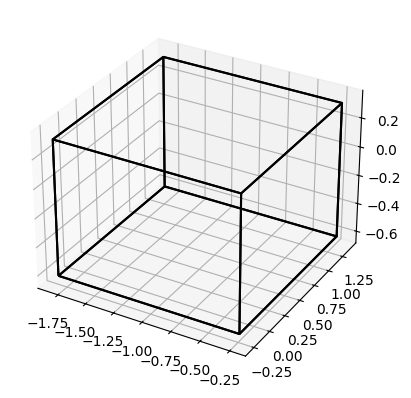

In [3]:
max_p, min_p = ([np.float64(-0.23350), np.float64(1.37460), np.float64(0.31949)], [np.float64(-1.81833),np.float64(-0.26129),np.float64(-0.61740)])

Theta = Polytope(A=np.block([[np.eye(3)], [-np.eye(3)]]), b=np.block([np.array(max_p), -np.array(min_p)]))  # np.block([np.array(max_p), -np.array(min_p)])
Theta.plot()
Theta.V

SetUpdater(A_B, C.transpose(2, 0, 1), Theta, Theta_c, W, E, 1)

In [4]:
theta_v = np.concatenate((np.ones((8,1)),Theta.V), 1) 
Av = np.einsum('ijk,lk->ijl', A, theta_v)
Bv = np.einsum('ijk,lk->ijl', B, theta_v)

In [ ]:
z = Polytope(A=np.block([[np.eye(6)], [-np.eye(6)]]), b=np.concatenate(([1e10, 0.46, 0.01, 1.90, 0.46, 1.90], np.array([1e10, 0.46, 0.01, 1.90, 0.46, 1.90]))))

Q = np.eye(4)
R = np.eye(2)
# R = np.diag([1/(0.46**2), 1/(1.90**2)])  # np.diag([1/(0.46**2), 1/(1.90**2), 1, 1])
gain_synth = GainSynthesis(
            Av, Bv,
            Q=Q, R=R,
            Z_bnd=z, W=Polytope(),
            mode='LQR', contraction_factor=0.98)
gain_synth.synthesize_controller()

In [ ]:
K = gain_synth.get_gain()
P = gain_synth.get_terminal_weight()

In [ ]:
P, K

(array([[ 1.90584932e+04, -3.11708260e+04, -2.18046990e+04,
         -3.82077431e+05],
        [-3.11708260e+04,  1.35038780e+07,  1.21994189e+07,
         -1.29229345e+07],
        [-2.18046990e+04,  1.21994189e+07,  1.24390961e+07,
         -1.31640429e+07],
        [-3.82077431e+05, -1.29229345e+07, -1.31640429e+07,
          5.73129788e+07]]),
 array([[-7.57855882e-03, -6.40593493e-01, -1.83721441e-01,
          5.62371887e-01],
        [-5.07279439e-05,  8.12719728e-02,  7.37019877e-02,
          6.28097473e-02]]))